In [ ]:
!pip install -q tensorflow scikit-learn seaborn

In [ ]:
import os
import zipfile
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.applications import MobileNetV2

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [ ]:
from google.colab import files

uploaded = files.upload()

zip_file = list(uploaded.keys())[0]

print("Uploaded:", zip_file)

Saving archive (1).zip to archive (1).zip
Uploaded: archive (1).zip


In [ ]:
EXTRACT_DIR = "/content/currency_dataset"

if os.path.exists(EXTRACT_DIR):
    shutil.rmtree(EXTRACT_DIR)

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [ ]:
for root, dirs, files in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

    if level >= 3:
        dirs[:] = []

currency_dataset/
    Indian Currency Dataset/
        test/
            real/
                test (32).jpg
                test (17).jpg
                test (18).jpg
                test (37).jpg
                test (27).jpg
            fake/
                test (17).jpg
                test (18).jpg
                test (37).jpg
                test (27).jpg
                ss.jpg
        train/
            real/
                1 (29).jpg
                1 (87).jpg
                1 (55).jpg
                1 (34).jpg
                1 (104).jpg
            fake/
                1 (29).jpg
                1 (87).jpg
                1 (55).jpg
                1 (34).jpg
                1 (104).jpg


In [ ]:
REAL_NAMES = {
    "real",
    "genuine",
    "genuine notes",
    "real notes",
    "original",
    "authentic",
    "true"
}

FAKE_NAMES = {
    "fake",
    "counterfeit",
    "counterfeit notes",
    "fake notes",
    "forged",
    "false"
}

def normalize_name(name):
    return name.lower().strip().replace("_", " ").replace("-", " ")

real_dirs = []
fake_dirs = []

for root, dirs, files in os.walk(EXTRACT_DIR):

    folder_name = normalize_name(os.path.basename(root))

    image_count = sum(
        1 for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    )

    if image_count == 0:
        continue

    if folder_name in REAL_NAMES:
        real_dirs.append(root)

    if folder_name in FAKE_NAMES:
        fake_dirs.append(root)

print("REAL folders:")
for x in real_dirs:
    print(x)

print("\nFAKE folders:")
for x in fake_dirs:
    print(x)

REAL folders:
/content/currency_dataset/Indian Currency Dataset/test/real
/content/currency_dataset/Indian Currency Dataset/train/real

FAKE folders:
/content/currency_dataset/Indian Currency Dataset/test/fake
/content/currency_dataset/Indian Currency Dataset/train/fake


In [ ]:
if len(real_dirs) == 0 or len(fake_dirs) == 0:

    print("❌ REAL/FAKE labels were NOT detected.")
    print()
    print("The dataset appears not to have explicit REAL and FAKE folders.")
    print()
    print("A valid authenticity dataset needs labels such as:")
    print("    REAL / FAKE")
    print("    GENUINE / COUNTERFEIT")
    print()
    print("The model will NOT be trained because converting denomination")
    print("labels into REAL/FAKE would produce invalid results.")

    raise ValueError(
        "No valid REAL/FAKE labels found in the dataset."
    )

else:

    print("✅ REAL/FAKE dataset detected.")

✅ REAL/FAKE dataset detected.


In [ ]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

data = []

for folder in real_dirs:

    for root, dirs, files in os.walk(folder):

        for file in files:

            if file.lower().endswith(image_extensions):

                data.append({
                    "filepath": os.path.join(root, file),
                    "label": 0,
                    "class": "REAL"
                })


for folder in fake_dirs:

    for root, dirs, files in os.walk(folder):

        for file in files:

            if file.lower().endswith(image_extensions):

                data.append({
                    "filepath": os.path.join(root, file),
                    "label": 1,
                    "class": "FAKE"
                })


df = pd.DataFrame(data)

print("Total images:", len(df))
print()

print(df["class"].value_counts())

Total images: 355

class
FAKE    187
REAL    168
Name: count, dtype: int64


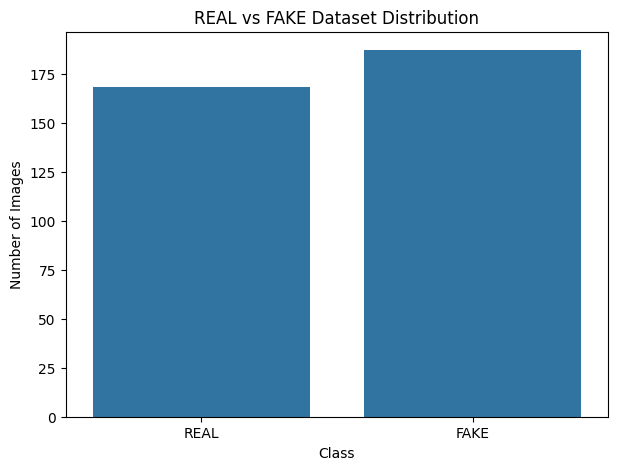

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="class"
)

plt.title("REAL vs FAKE Dataset Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

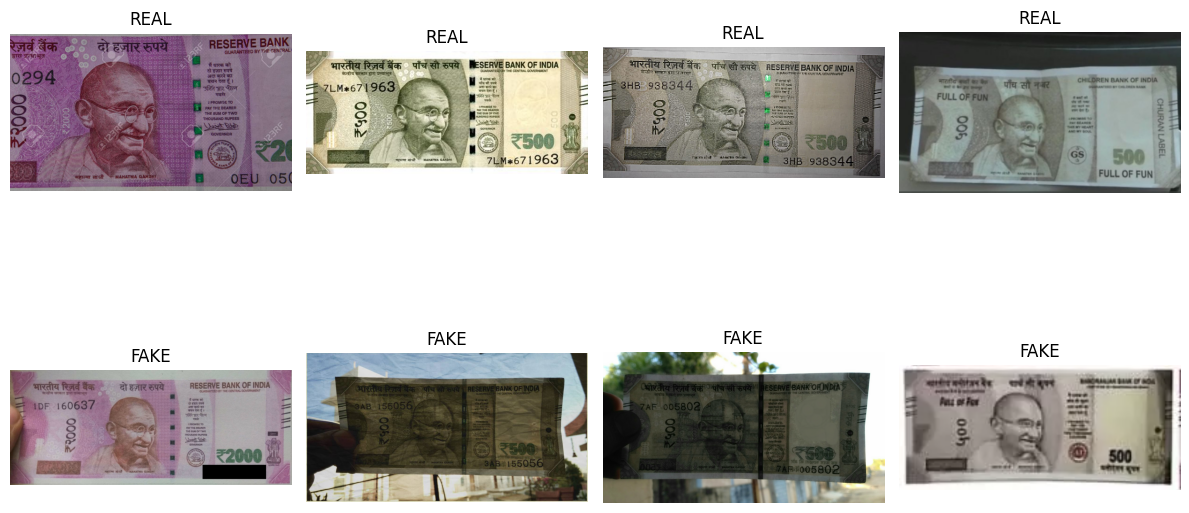

In [ ]:
plt.figure(figsize=(12,8))

sample_df = pd.concat([
    df[df["label"] == 0].sample(
        min(4, len(df[df["label"] == 0])),
        random_state=42
    ),
    df[df["label"] == 1].sample(
        min(4, len(df[df["label"] == 1])),
        random_state=42
    )
])

for i, (_, row) in enumerate(sample_df.iterrows()):

    img = plt.imread(row["filepath"])

    plt.subplot(2,4,i+1)
    plt.imshow(img)
    plt.title(row["class"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 248
Validation: 53
Testing: 54


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    directory=os.path.dirname(real_dirs[0]),
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 107 files.


In [ ]:
def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, IMG_SIZE)

    image = tf.cast(image, tf.float32)

    return image, tf.cast(label, tf.float32)


def make_dataset(dataframe, shuffle=False):

    paths = dataframe["filepath"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Datasets created.")

Datasets created.


In [ ]:
classes = np.unique(train_df["label"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"]
)

class_weights = dict(
    zip(classes, weights)
)

print("Class weights:")
print(class_weights)

Class weights:
{np.int64(0): np.float64(1.0598290598290598), np.int64(1): np.float64(0.9465648854961832)}


In [ ]:
data_augmentation = keras.Sequential([

    layers.RandomRotation(
        0.08
    ),

    layers.RandomZoom(
        height_factor=(-0.12, 0.12),
        width_factor=(-0.12, 0.12)
    ),

    layers.RandomTranslation(
        height_factor=0.06,
        width_factor=0.06
    ),

    layers.RandomContrast(
        0.15
    ),

], name="currency_augmentation")

print("Stronger data augmentation enabled.")

Stronger data augmentation enabled.


In [ ]:
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False


inputs = keras.Input(
    shape=(224, 224, 3)
)

# Data augmentation
x = data_augmentation(inputs)

# MobileNetV2 preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Feature extraction
x = base_model(
    x,
    training=False
)

# Global pooling
x = layers.GlobalAveragePooling2D()(x)

# Smaller dense layer + stronger L2
x = layers.Dense(
    64,
    activation="relu",
    kernel_regularizer=regularizers.l1_l2(
        l1=1e-6,
        l2=5e-4
    )
)(x)

# Batch normalization
x = layers.BatchNormalization()(x)

# Higher dropout
x = layers.Dropout(
    0.50
)(x)

# Binary output
outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = keras.Model(
    inputs,
    outputs
)

model.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ currency_augmentation           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_2 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_2 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,289 (8.93 MB)

 Trainable params: 82,177 (321.00 KB)

 Non-trainable params: 2,258,112 (8.61 MB)

In [ ]:
loss_function = keras.losses.BinaryCrossentropy(
    label_smoothing=0.05
)

model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=2e-4
    ),

    loss=loss_function,

    metrics=[
        keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        keras.metrics.Precision(
            name="precision"
        ),

        keras.metrics.Recall(
            name="recall"
        )
    ]
)

print("Improved model compiled successfully.")

Improved model compiled successfully.


In [ ]:
early_stopping = keras.callbacks.EarlyStopping(

    monitor="val_loss",

    mode="min",

    patience=6,

    min_delta=0.002,

    restore_best_weights=True,

    verbose=1
)


reduce_lr = keras.callbacks.ReduceLROnPlateau(

    monitor="val_loss",

    mode="min",

    factor=0.3,

    patience=2,

    min_lr=1e-7,

    verbose=1
)


checkpoint = keras.callbacks.ModelCheckpoint(

    "/content/best_currency_model.keras",

    monitor="val_loss",

    mode="min",

    save_best_only=True,

    verbose=1
)

print("Callbacks ready.")

Callbacks ready.


In [ ]:
EPOCHS = 30

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS,

    class_weight=class_weights,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Epoch 1/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5084 - loss: 1.0914 - precision: 0.4806 - recall: 0.5311
Epoch 1: val_loss improved from None to 0.79349, saving model to /content/best_currency_model.keras

Epoch 1: finished saving model to /content/best_currency_model.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 34s 3s/step - accuracy: 0.5565 - loss: 0.9686 - precision: 0.5840 - recall: 0.5573 - val_accuracy: 0.5472 - val_loss: 0.7935 - val_precision: 0.5417 - val_recall: 0.9286 - learning_rate: 2.0000e-04
Epoch 2/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7034 - loss: 0.7716 - precision: 0.6994 - recall: 0.7131
Epoch 2: val_loss improved from 0.79349 to 0.76298, saving model to /content/best_currency_model.keras

Epoch 2: finished saving model to /content/best_currency_model.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.6976 - loss: 0.7659 - precision: 0.7154 - recall: 0.7099 - val_accuracy: 0.5283 - val_loss: 0.7630 - val_precision: 0.5306 - val_recall: 0.9286 - l

In [ ]:
best_epoch = (
    np.argmin(
        history.history["val_loss"]
    ) + 1
)

best_val_loss = min(
    history.history["val_loss"]
)

best_val_accuracy = max(
    history.history["val_accuracy"]
)

print("=" * 45)

print(
    f"Best Epoch          : {best_epoch}"
)

print(
    f"Best Validation Loss: {best_val_loss:.4f}"
)

print(
    f"Best Validation Accuracy: "
    f"{best_val_accuracy * 100:.2f}%"
)

print("=" * 45)

Best Epoch          : 10
Best Validation Loss: 0.5865
Best Validation Accuracy: 77.36%


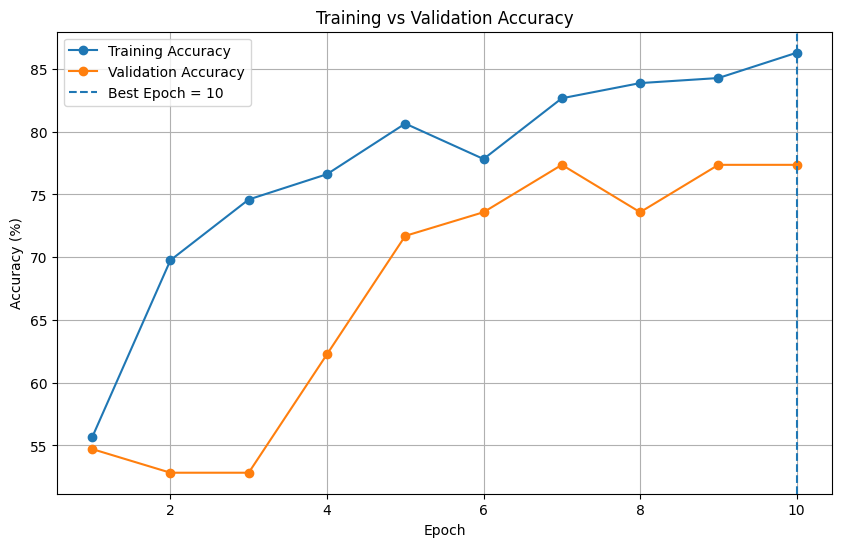

In [ ]:
epochs_to_show = np.arange(
    1,
    best_epoch + 1
)

train_acc = (
    history.history["accuracy"][:best_epoch]
)

val_acc = (
    history.history["val_accuracy"][:best_epoch]
)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_to_show,
    np.array(train_acc) * 100,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_to_show,
    np.array(val_acc) * 100,
    marker="o",
    label="Validation Accuracy"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "Training vs Validation Accuracy"
)

plt.legend()

plt.grid(True)

plt.show()

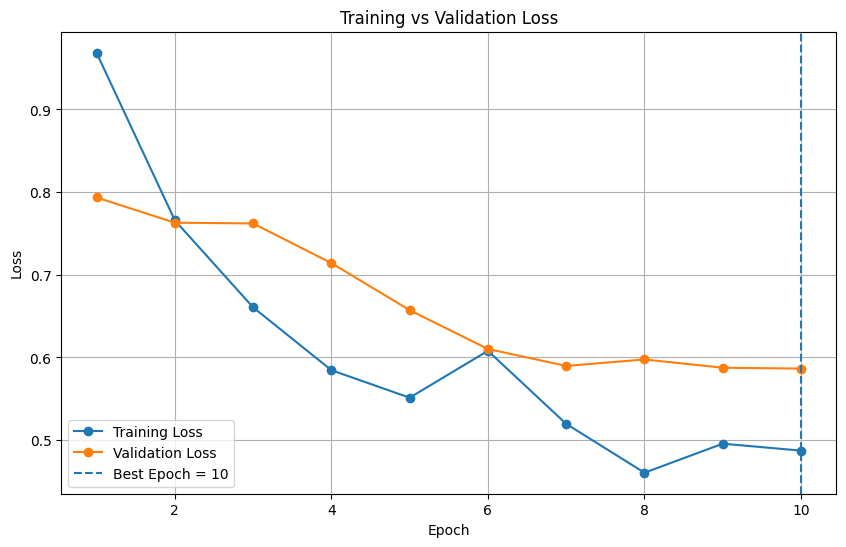

In [ ]:
train_loss = (
    history.history["loss"][:best_epoch]
)

val_loss = (
    history.history["val_loss"][:best_epoch]
)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_to_show,
    train_loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_to_show,
    val_loss,
    marker="o",
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training vs Validation Loss"
)

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
base_model.trainable = True

# Freeze all layers except last 20
for layer in base_model.layers[:-20]:

    layer.trainable = False


# Keep BatchNormalization frozen
for layer in base_model.layers:

    if isinstance(
        layer,
        layers.BatchNormalization
    ):

        layer.trainable = False


trainable_layers = sum(
    1
    for layer in base_model.layers
    if layer.trainable
)

print(
    "Trainable MobileNetV2 layers:",
    trainable_layers
)

Trainable MobileNetV2 layers: 13


In [ ]:
model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss=keras.losses.BinaryCrossentropy(
        label_smoothing=0.05
    ),

    metrics=[
        keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        keras.metrics.Precision(
            name="precision"
        ),

        keras.metrics.Recall(
            name="recall"
        )
    ]
)

print(
    "Fine-tuning model compiled."
)

Fine-tuning model compiled.


In [ ]:
fine_tune_early_stop = keras.callbacks.EarlyStopping(

    monitor="val_loss",

    mode="min",

    patience=5,

    min_delta=0.001,

    restore_best_weights=True,

    verbose=1
)


fine_tune_reduce_lr = keras.callbacks.ReduceLROnPlateau(

    monitor="val_loss",

    mode="min",

    factor=0.3,

    patience=2,

    min_lr=1e-8,

    verbose=1
)


fine_tune_checkpoint = keras.callbacks.ModelCheckpoint(

    "/content/best_currency_model.keras",

    monitor="val_loss",

    mode="min",

    save_best_only=True,

    verbose=1
)


fine_tune_history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=15,

    class_weight=class_weights,

    callbacks=[
        fine_tune_early_stop,
        fine_tune_reduce_lr,
        fine_tune_checkpoint
    ],

    verbose=1
)

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8186 - loss: 0.5774 - precision: 0.8827 - recall: 0.7648
Epoch 1: val_loss improved from None to 0.56744, saving model to /content/best_currency_model.keras

Epoch 1: finished saving model to /content/best_currency_model.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.8306 - loss: 0.5421 - precision: 0.8938 - recall: 0.7710 - val_accuracy: 0.7736 - val_loss: 0.5674 - val_precision: 0.7222 - val_recall: 0.9286 - learning_rate: 1.0000e-05
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8662 - loss: 0.4411 - precision: 0.9050 - recall: 0.8252
Epoch 2: val_loss improved from 0.56744 to 0.55394, saving model to /content/best_currency_model.keras

Epoch 2: finished saving model to /content/best_currency_model.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.8589 - loss: 0.4500 - precision: 0.8934 - recall: 0.8321 - val_accuracy: 0.7736 - val_loss: 0.5539 - val_precision: 0.7222 - val_recall: 0.9286 - l

In [ ]:
combined_accuracy = (
    history.history["accuracy"]
    +
    fine_tune_history.history["accuracy"]
)

combined_val_accuracy = (
    history.history["val_accuracy"]
    +
    fine_tune_history.history["val_accuracy"]
)

combined_loss = (
    history.history["loss"]
    +
    fine_tune_history.history["loss"]
)

combined_val_loss = (
    history.history["val_loss"]
    +
    fine_tune_history.history["val_loss"]
)

best_epoch = (
    np.argmax(combined_val_accuracy) + 1
)

print(
    "Final Best Epoch:",
    best_epoch
)

print(
    "Best Validation Accuracy:",
    f"{max(combined_val_accuracy)*100:.2f}%"
)

Final Best Epoch: 27
Best Validation Accuracy: 88.68%


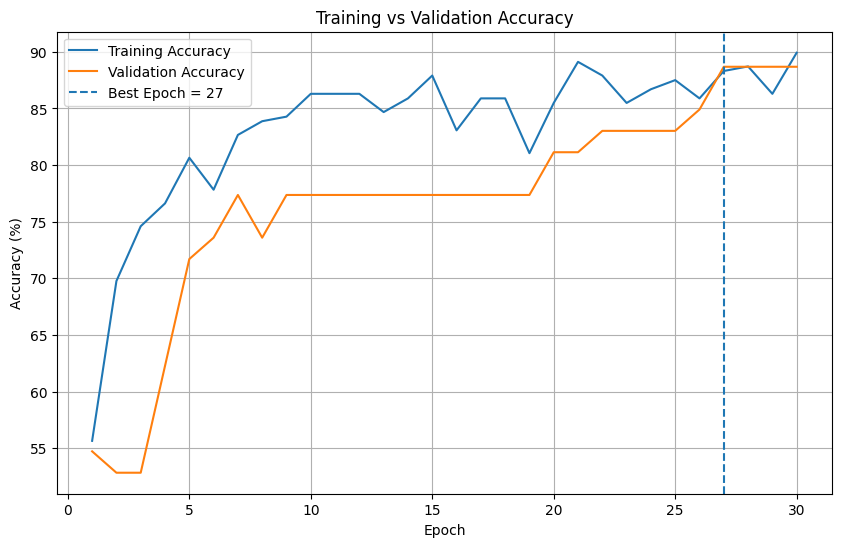

In [ ]:
epochs_all = np.arange(
    1,
    len(combined_accuracy) + 1
)

plt.figure(figsize=(10,6))

plt.plot(
    epochs_all,
    np.array(combined_accuracy) * 100,
    label="Training Accuracy"
)

plt.plot(
    epochs_all,
    np.array(combined_val_accuracy) * 100,
    label="Validation Accuracy"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "Training vs Validation Accuracy"
)

plt.legend()
plt.grid(True)

plt.show()

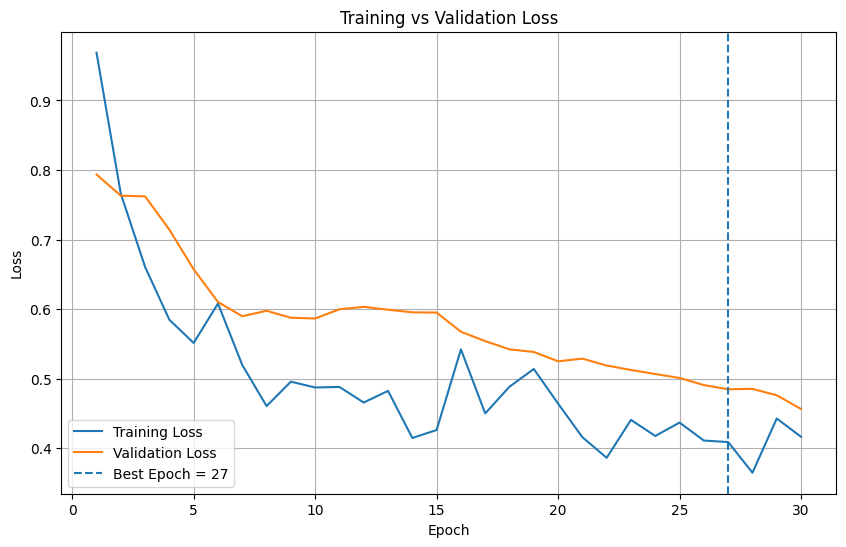

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(
    epochs_all,
    combined_loss,
    label="Training Loss"
)

plt.plot(
    epochs_all,
    combined_val_loss,
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training vs Validation Loss"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

print("================================")
print("       MODEL PERFORMANCE")
print("================================")

print(
    f"Accuracy  : {accuracy*100:.2f}%"
)

print(
    f"Precision : {precision*100:.2f}%"
)

print(
    f"Recall    : {recall*100:.2f}%"
)

print(
    f"F1 Score  : {f1*100:.2f}%"
)

       MODEL PERFORMANCE
Accuracy  : 88.89%
Precision : 82.35%
Recall    : 100.00%
F1 Score  : 90.32%


In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "REAL",
            "FAKE"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

        REAL       1.00      0.77      0.87        26
        FAKE       0.82      1.00      0.90        28

    accuracy                           0.89        54
   macro avg       0.91      0.88      0.89        54
weighted avg       0.91      0.89      0.89        54



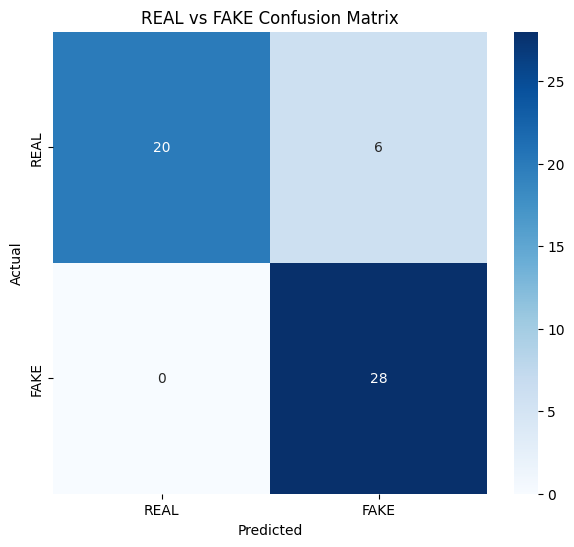

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["REAL", "FAKE"],
    yticklabels=["REAL", "FAKE"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("REAL vs FAKE Confusion Matrix")

plt.show()

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

precision_values, recall_values, f1_values, _ = \
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0,1],
        zero_division=0
    )

metrics_df = pd.DataFrame({

    "Class": ["REAL", "FAKE"],

    "Precision": precision_values,

    "Recall": recall_values,

    "F1 Score": f1_values

})

metrics_df

,Class,Precision,Recall,F1 Score
0,REAL,1.000000,0.769231,0.869565
1,FAKE,0.823529,1.000000,0.903226


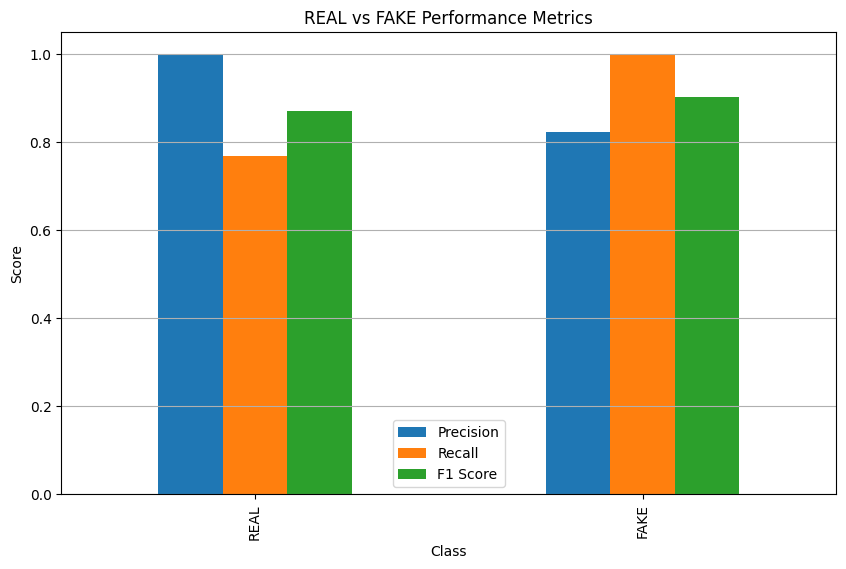

In [ ]:
metrics_df.set_index("Class").plot(
    kind="bar",
    figsize=(10,6)
)

plt.title(
    "REAL vs FAKE Performance Metrics"
)

plt.ylabel("Score")

plt.ylim(0,1.05)

plt.grid(axis="y")

plt.show()

In [ ]:
best_train_accuracy = max(
    combined_accuracy
)

# Best validation accuracy
best_validation_accuracy = max(
    combined_val_accuracy
)


training_error = (
    1 - best_train_accuracy
)

validation_error = (
    1 - best_validation_accuracy
)


bias = validation_error


variance = abs(
    best_train_accuracy -
    best_validation_accuracy
)



train_val_gap = variance



print("=" * 55)
print("              BIAS / VARIANCE ANALYSIS")
print("=" * 55)

print()

print(
    f"Training Accuracy       : "
    f"{best_train_accuracy * 100:.2f}%"
)

print(
    f"Validation Accuracy     : "
    f"{best_validation_accuracy * 100:.2f}%"
)

print()

print(
    f"Training Error          : "
    f"{training_error * 100:.2f}%"
)

print(
    f"Validation Error        : "
    f"{validation_error * 100:.2f}%"
)

print()

print(
    f"Empirical Bias          : "
    f"{bias * 100:.2f}%"
)

print(
    f"Empirical Variance      : "
    f"{variance * 100:.2f}%"
)

print(
    f"Train-Val Gap           : "
    f"{train_val_gap * 100:.2f}%"
)

print()


if variance < 0.05:

    print("Interpretation: LOW VARIANCE")
    print("The model has a small train-validation gap.")

elif variance < 0.10:

    print("Interpretation: MODERATE VARIANCE")
    print("There is some difference between training and validation performance.")

else:

    print("Interpretation: HIGH VARIANCE")
    print("The model shows signs of overfitting.")

print("=" * 55)

              BIAS / VARIANCE ANALYSIS

Training Accuracy       : 89.92%
Validation Accuracy     : 88.68%

Training Error          : 10.08%
Validation Error        : 11.32%

Empirical Bias          : 11.32%
Empirical Variance      : 1.24%
Train-Val Gap           : 1.24%

Interpretation: LOW VARIANCE
The model has a small train-validation gap.


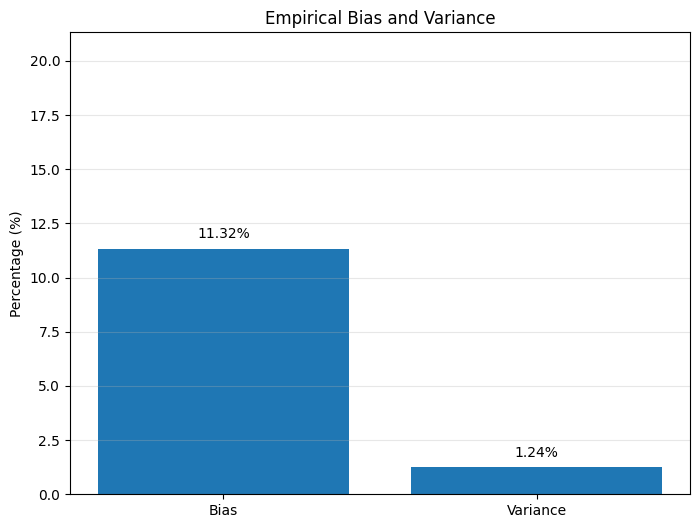

In [ ]:
labels = [
    "Bias",
    "Variance"
]

values = [
    bias * 100,
    variance * 100
]

plt.figure(figsize=(8, 6))

bars = plt.bar(
    labels,
    values
)

plt.ylabel("Percentage (%)")

plt.title(
    "Empirical Bias and Variance"
)

plt.ylim(
    0,
    max(values) + 10
)

# Display values
for bar, value in zip(
    bars,
    values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

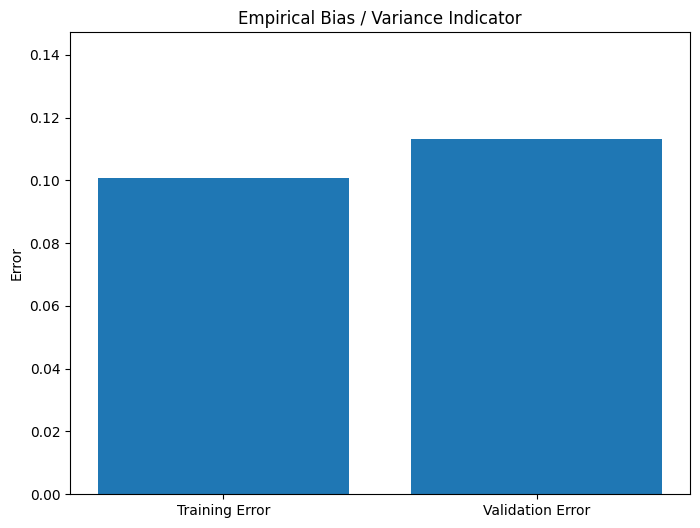

In [ ]:
labels = [
    "Training Error",
    "Validation Error"
]

values = [
    train_error,
    validation_error
]

plt.figure(figsize=(8,6))

plt.bar(
    labels,
    values
)

plt.ylabel("Error")

plt.title(
    "Empirical Bias / Variance Indicator"
)

plt.ylim(
    0,
    max(values) * 1.3
)

plt.show()

In [ ]:
X = df["filepath"].values

y = df["label"].values

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y),
    start=1
):

    print("\n==============================")
    print(f"FOLD {fold}")
    print("==============================")

    fold_train_df = df.iloc[train_idx]
    fold_val_df = df.iloc[val_idx]

    fold_train_ds = make_dataset(
        fold_train_df,
        shuffle=True
    )

    fold_val_ds = make_dataset(
        fold_val_df
    )

    cv_model = keras.models.clone_model(model)

    cv_model.set_weights(
        model.get_weights()
    )

    cv_model.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=1e-5
        ),

        loss="binary_crossentropy",

        metrics=["accuracy"]
    )

    history_cv = cv_model.fit(

        fold_train_ds,

        validation_data=fold_val_ds,

        epochs=5,

        verbose=0
    )

    score = max(
        history_cv.history["val_accuracy"]
    )

    cv_scores.append(score)

    print(
        f"Fold {fold} Accuracy: "
        f"{score*100:.2f}%"
    )


FOLD 1
Fold 1 Accuracy: 88.73%

FOLD 2
Fold 2 Accuracy: 88.73%

FOLD 3
Fold 3 Accuracy: 90.14%

FOLD 4
Fold 4 Accuracy: 87.32%

FOLD 5
Fold 5 Accuracy: 87.32%


In [ ]:
print("\n================================")
print("   5-FOLD CROSS VALIDATION")
print("================================")

for i, score in enumerate(
    cv_scores,
    start=1
):

    print(
        f"Fold {i}: {score*100:.2f}%"
    )

print(
    f"\nMean CV Accuracy: "
    f"{np.mean(cv_scores)*100:.2f}%"
)

print(
    f"Standard Deviation: "
    f"{np.std(cv_scores)*100:.2f}%"
)


   5-FOLD CROSS VALIDATION
Fold 1: 88.73%
Fold 2: 88.73%
Fold 3: 90.14%
Fold 4: 87.32%
Fold 5: 87.32%

Mean CV Accuracy: 88.45%
Standard Deviation: 1.05%


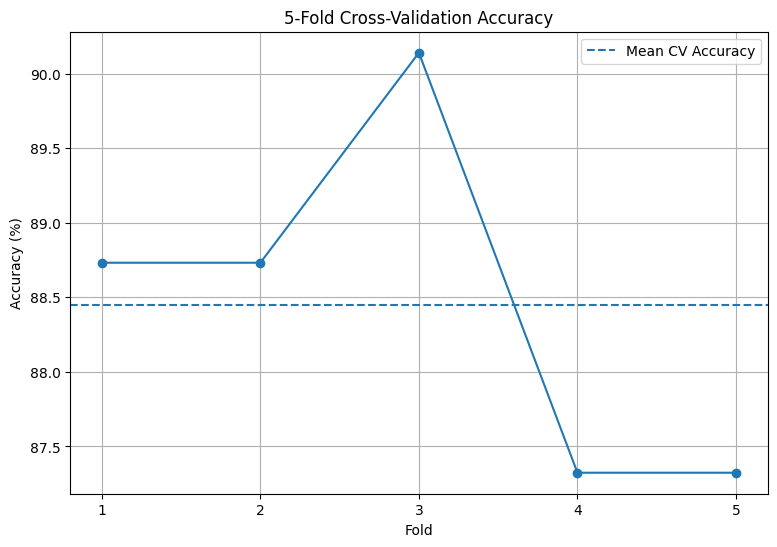

In [ ]:
fold_numbers = np.arange(
    1,
    6
)

plt.figure(figsize=(9,6))

plt.plot(
    fold_numbers,
    np.array(cv_scores) * 100,
    marker="o"
)

plt.axhline(
    np.mean(cv_scores) * 100,
    linestyle="--",
    label="Mean CV Accuracy"
)

plt.xlabel("Fold")

plt.ylabel("Accuracy (%)")

plt.title(
    "5-Fold Cross-Validation Accuracy"
)

plt.xticks(fold_numbers)

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
model.save(
    "/content/indian_currency_real_fake_model.keras"
)

print(
    "Model saved successfully."
)

Model saved successfully.


In [ ]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

img = load_img(
    image_path,
    target_size=(224,224)
)

img_array = img_to_array(img)

img_array = np.expand_dims(
    img_array,
    axis=0
)

prediction = model.predict(
    img_array,
    verbose=0
)[0][0]

fake_probability = prediction

real_probability = 1 - prediction

print("\n================================")
print("       CURRENCY RESULT")
print("================================")

if fake_probability >= 0.5:

    print("RESULT: FAKE")

    print(
        f"Fake Probability: "
        f"{fake_probability*100:.2f}%"
    )

    print(
        f"Real Probability: "
        f"{real_probability*100:.2f}%"
    )

else:

    print("RESULT: REAL")

    print(
        f"Real Probability: "
        f"{real_probability*100:.2f}%"
    )

    print(
        f"Fake Probability: "
        f"{fake_probability*100:.2f}%"
    )

Saving fakenote.jpeg to fakenote.jpeg

       CURRENCY RESULT
RESULT: FAKE
Fake Probability: 57.53%
Real Probability: 42.47%


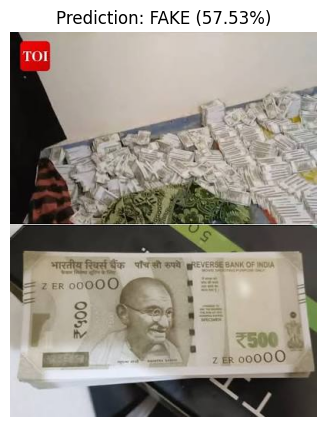

In [ ]:
plt.figure(figsize=(8,5))

plt.imshow(
    load_img(image_path)
)

plt.axis("off")

if fake_probability >= 0.5:

    plt.title(
        f"Prediction: FAKE "
        f"({fake_probability*100:.2f}%)"
    )

else:

    plt.title(
        f"Prediction: REAL "
        f"({real_probability*100:.2f}%)"
    )

plt.show()

In [ ]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

img = load_img(
    image_path,
    target_size=(224,224)
)

img_array = img_to_array(img)

img_array = np.expand_dims(
    img_array,
    axis=0
)

prediction = model.predict(
    img_array,
    verbose=0
)[0][0]

fake_probability = prediction

real_probability = 1 - prediction

print("\n================================")
print("       CURRENCY RESULT")
print("================================")

if fake_probability >= 0.5:

    print("RESULT: FAKE")

    print(
        f"Fake Probability: "
        f"{fake_probability*100:.2f}%"
    )

    print(
        f"Real Probability: "
        f"{real_probability*100:.2f}%"
    )

else:

    print("RESULT: REAL")

    print(
        f"Real Probability: "
        f"{real_probability*100:.2f}%"
    )

    print(
        f"Fake Probability: "
        f"{fake_probability*100:.2f}%"
    )

Saving RealNote.jpeg to RealNote.jpeg

       CURRENCY RESULT
RESULT: REAL
Real Probability: 79.80%
Fake Probability: 20.20%


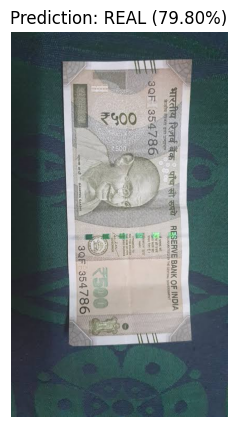

In [ ]:
plt.figure(figsize=(8,5))

plt.imshow(
    load_img(image_path)
)

plt.axis("off")

if fake_probability >= 0.5:

    plt.title(
        f"Prediction: FAKE "
        f"({fake_probability*100:.2f}%)"
    )

else:

    plt.title(
        f"Prediction: REAL "
        f"({real_probability*100:.2f}%)"
    )

plt.show()